# XGBoost models: flood risk and earthquake severity
Prototype on historical data. This notebook reproduces the numbers in `reports/metrics.json` using the same code as `src/disaster_risk/`.

**Data** (not committed; place in `datasets/raw/`, see `datasets/README.md`): `flood1.csv`, `Eartquakes-1990-2023.csv` (or its `.zip`).

**Changes from the original notebook**
- Earthquake task is severity (Low < 4.0, Medium 4.0 to < 6.0, High >= 6.0), not event type. The original event-type model took `magnitudo` and `significance` as inputs and is not used.
- `magnitudo` and `significance` are not model inputs. Severity is defined from magnitude, and `significance` is derived from it (correlation 0.9455 on valid rows), so both leak the target. Inputs: longitude, latitude, depth. The tsunami flag is not an input because it is recorded after an event and is not known in advance.
- Rows with magnitude -10 (invalid sentinel) are dropped.
- The flood target uses the fixed threshold `FloodProbability >= 0.5`.
- CSV input (the `.xlsx` copy of the earthquake file is cut at 1,048,576 rows). No Colab upload cells.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

try:
    import disaster_risk  # works after `pip install -e .`
except ImportError:       # fallback when run from notebooks/ without installing
    sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from disaster_risk import config as C
from disaster_risk import metrics as M

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from xgboost import XGBClassifier
import xgboost
from disaster_risk.data import load_flood, load_earthquakes
from disaster_risk.train_flood import PARAMS as FLOOD_PARAMS
from disaster_risk.train_earthquake import PARAMS as EQ_PARAMS

print("xgboost", xgboost.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

xgboost 3.4.1 | numpy 2.3.5 | pandas 2.3.3


In [2]:
FLOOD_CSV = C.RAW_DIR / "flood1.csv"
EQ_PATH = next((p for p in [C.RAW_DIR / "Eartquakes-1990-2023.csv", C.RAW_DIR / "Eartquakes-1990-2023.zip"] if p.exists()), None)
print("flood file:", FLOOD_CSV, FLOOD_CSV.exists())
print("earthquake file:", EQ_PATH)
assert FLOOD_CSV.exists() and EQ_PATH is not None, "Put the raw files in datasets/raw/ first."
saved = M.load()  # reference numbers written by the training scripts

flood file: datasets/raw/flood1.csv True
earthquake file: datasets/raw/Eartquakes-1990-2023.csv


## Part 1: flood risk (binary, `FloodProbability >= 0.5`)

In [3]:
X_fl, y_fl = load_flood(FLOOD_CSV)
print("rows:", len(X_fl), "| features:", X_fl.shape[1])
print("flood class share:", round(float(y_fl.mean()), 4))
X_tr, X_te, y_tr, y_te = train_test_split(X_fl, y_fl, test_size=0.2, random_state=C.SEED, stratify=y_fl)
print("train:", X_tr.shape, "test:", X_te.shape)

rows: 50000 | features: 20
flood class share: 0.5103
train: (40000, 20) test: (10000, 20)


In [4]:
flood_model = XGBClassifier(**FLOOD_PARAMS).fit(X_tr, y_tr)
pred_fl = flood_model.predict(X_te)
acc_fl = accuracy_score(y_te, pred_fl)
print(f"Flood test accuracy: {acc_fl:.4f}")
print(classification_report(y_te, pred_fl, target_names=["No flood", "Flood"]))

Flood test accuracy: 0.9446
              precision    recall  f1-score   support

    No flood       0.94      0.95      0.94      4897
       Flood       0.95      0.94      0.95      5103

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



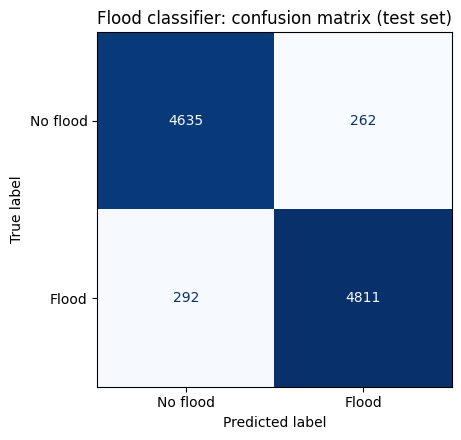

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_fl), display_labels=["No flood", "Flood"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Flood classifier: confusion matrix (test set)")
plt.tight_layout(); plt.show()

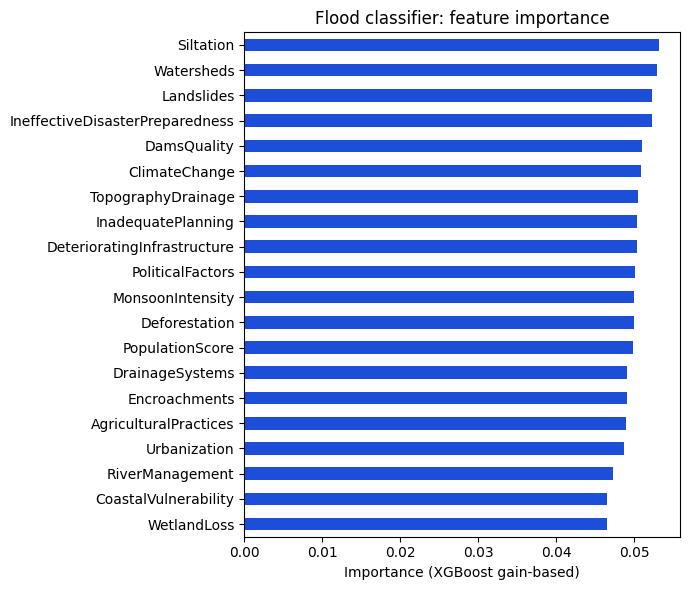

In [6]:
imp = pd.Series(flood_model.feature_importances_, index=X_fl.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 6))
imp.plot(kind="barh", ax=ax, color="#1D4ED8")
ax.set_xlabel("Importance (XGBoost gain-based)"); ax.set_title("Flood classifier: feature importance")
plt.tight_layout(); plt.show()

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEED)
cv_scores = cross_val_score(XGBClassifier(**FLOOD_PARAMS), X_fl, y_fl, cv=cv, scoring="accuracy")
print("5-fold CV accuracy per fold:", [round(float(s), 4) for s in cv_scores])
print(f"mean {cv_scores.mean():.4f} | std {cv_scores.std():.4f}")

5-fold CV accuracy per fold: [0.9473, 0.9479, 0.9492, 0.9488, 0.952]
mean 0.9490 | std 0.0016


In [8]:
ref = saved["flood"]
checks = {
    "test_accuracy": (round(float(acc_fl), 4), ref["test_accuracy"]),
    "cv5_accuracy_mean": (round(float(cv_scores.mean()), 4), ref["cv5_accuracy_mean"]),
    "cv5_accuracy_std": (round(float(cv_scores.std()), 4), ref["cv5_accuracy_std"]),
}
for k, (got, want) in checks.items():
    print(f"{k:20s} this run {got} | metrics.json {want} | match: {got == want}")

test_accuracy        this run 0.9446 | metrics.json 0.9446 | match: True
cv5_accuracy_mean    this run 0.949 | metrics.json 0.949 | match: True
cv5_accuracy_std     this run 0.0016 | metrics.json 0.0016 | match: True


## Part 2: earthquake severity (3 classes, inputs: longitude, latitude, depth)

In [9]:
X_eq, y_eq, info = load_earthquakes(EQ_PATH)
print(info)
counts = {C.SEVERITY_LABELS[i]: int((y_eq == i).sum()) for i in range(3)}
print("class counts:", counts)
X_tr_e, X_te_e, y_tr_e, y_te_e = train_test_split(X_eq, y_eq, test_size=0.2, random_state=C.SEED, stratify=y_eq)
baseline = float((y_te_e == int(np.bincount(y_te_e).argmax())).mean())
print(f"majority-class baseline accuracy (test set): {baseline:.4f}")

{'rows_raw': 3445751, 'rows_dropped_missing': 0, 'rows_dropped_invalid_magnitude': 647, 'rows_used': 3445104}
class counts: {'Low': 3062035, 'Medium': 378128, 'High': 4941}


majority-class baseline accuracy (test set): 0.8888


In [10]:
# Training on 3.4 million rows takes several minutes. By default the saved model is evaluated on the
# identical split. Set RETRAIN = True to train again with the same parameters (the file is not overwritten).
RETRAIN = False
if RETRAIN:
    eq_model = XGBClassifier(**EQ_PARAMS).fit(X_tr_e, y_tr_e)
else:
    eq_model = XGBClassifier()
    eq_model.load_model(C.MODELS_DIR / "earthquake_severity_xgb.json")
pred_eq = eq_model.predict(X_te_e)
acc_eq = accuracy_score(y_te_e, pred_eq)
f1_eq = f1_score(y_te_e, pred_eq, average="macro")
print(f"Earthquake test accuracy: {acc_eq:.4f} | macro F1: {f1_eq:.4f} | retrained: {RETRAIN}")
print(classification_report(y_te_e, pred_eq, target_names=C.SEVERITY_LABELS))

Earthquake test accuracy: 0.9754 | macro F1: 0.6299 | retrained: False
              precision    recall  f1-score   support

         Low       0.99      0.99      0.99    612407
      Medium       0.87      0.91      0.89     75626
        High       0.30      0.01      0.01       988

    accuracy                           0.98    689021
   macro avg       0.72      0.63      0.63    689021
weighted avg       0.97      0.98      0.97    689021



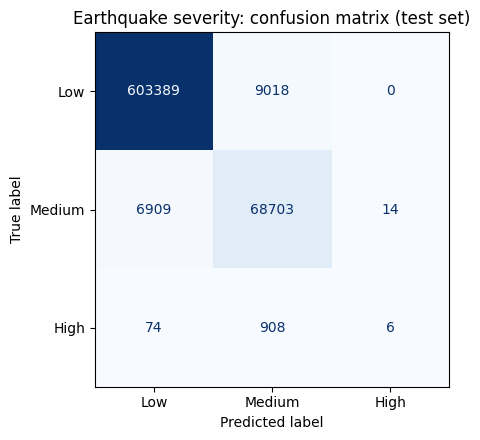

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te_e, pred_eq), display_labels=C.SEVERITY_LABELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Earthquake severity: confusion matrix (test set)")
plt.tight_layout(); plt.show()

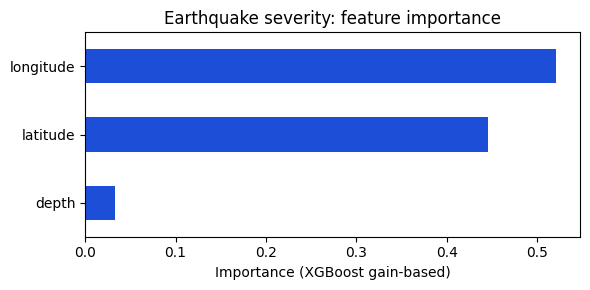

In [12]:
imp_eq = pd.Series(eq_model.feature_importances_, index=C.EQ_FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
imp_eq.plot(kind="barh", ax=ax, color="#1D4ED8")
ax.set_xlabel("Importance (XGBoost gain-based)"); ax.set_title("Earthquake severity: feature importance")
plt.tight_layout(); plt.show()

In [13]:
ref = saved["earthquake_severity"]["saved_model"]
rep = classification_report(y_te_e, pred_eq, target_names=C.SEVERITY_LABELS, output_dict=True)
checks = {
    "test_accuracy": (round(float(acc_eq), 4), ref["test_accuracy"]),
    "test_macro_f1": (round(float(f1_eq), 4), ref["test_macro_f1"]),
    "High recall": (round(rep["High"]["recall"], 4), round(ref["report"]["High"]["recall"], 4)),
    "baseline accuracy": (round(baseline, 4), saved["earthquake_severity"]["majority_class_baseline_accuracy"]),
}
for k, (got, want) in checks.items():
    print(f"{k:18s} this run {got} | metrics.json {want} | match: {got == want}")

test_accuracy      this run 0.9754 | metrics.json 0.9754 | match: True
test_macro_f1      this run 0.6299 | metrics.json 0.6299 | match: True
High recall        this run 0.0061 | metrics.json 0.0061 | match: True
baseline accuracy  this run 0.8888 | metrics.json 0.8888 | match: True


## Limits
- The High class (magnitude >= 6.0) is rare and is hard to detect from location and depth alone. Read its recall in the classification report above, not only the overall accuracy: overall accuracy is compared against the majority-class baseline printed in Part 2.
- A random train/test split puts aftershocks of the same event in both sets, so the test scores are optimistic.
- This is a model of historical records. It does not forecast earthquakes.